# 🎬 Classification de résumés de films — Horreur vs Comédie

**Projet :** Deep Learning — Create, Optimize, Push to Prod
**Auteur :** TheRealRPI
**Date :** 22/10/2026

---

## Objectif
Créer, optimiser et sauvegarder un modèle de classification binaire capable de prédire si un résumé de film est un film d'**horreur** ou une **comédie**, à partir de son texte.

## Plan du notebook (8 parties)
1. **Audit et nettoyage** — Explorer et nettoyer les données
2. **Découpage du jeu de données** — Train / Validation / Test / Production (60/20/20)
3. **Représentation du texte (TF-IDF)** — Vectorisation
4. **Les points de comparaison** — Modèles de référence (LogReg, NB, NN simple)
5. **Recherche des réglages avec KerasTuner** — RandomSearch (20 essais)
6. **Recherche des réglages avec Optuna** — Comparaison avec KerasTuner
7. **Verdict sur le test** — Évaluation finale
8. **Sauvegarde** — Export du modèle et des artefacts

---
## 📦 Imports

Toutes les bibliothèques nécessaires pour le projet.

In [1]:
# ─── Données & manipulation ───────────────────────────────────────────────
import json
import os
import platform

# Pour éviter les messages d'avertissement de Tensor
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# ─── Utilitaires ──────────────────────────────────────────────────────────
import sys
from pathlib import Path

# ─── Sauvegarde ───────────────────────────────────────────────────────────
import joblib

# ─── KerasTuner : recherche d'hyperparamètres (partie 5) ──────────────────
import keras_tuner as kt

# ─── Visualisation ────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np

# ─── Optuna : recherche d'hyperparamètres (partie 6) ──────────────────────
import optuna
import pandas as pd
import sklearn

# ─── TensorFlow / Keras : deep learning ───────────────────────────────────
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# ─── Scikit-learn : prétraitement, modèles classiques, métriques ─────────
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping

# ─── Configuration ────────────────────────────────────────────────────────
# Graines pour la reproductibilité
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Paramètres d'entraînement — source unique de vérité pour tout le notebook
EPOCHS = 100  # budget max d'époques ; l'early stopping coupe avant si besoin
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.12  # part du train réservée à la validation
PATIENCE = 10  # early stopping : époques sans amélioration avant arrêt

# Vérification du GPU
print(f"TensorFlow version : {tf.__version__}")
print(f"GPU disponible : {len(tf.config.list_physical_devices('GPU')) > 0}")
if len(tf.config.list_physical_devices("GPU")) > 0:
    print(f"GPU : {tf.config.list_physical_devices('GPU')}")

# Chemins
DATA_PATH = Path("./Data/textes_films_horreur_comedie.csv")
MODEL_DIR = Path("./model")
MODEL_DIR.mkdir(exist_ok=True)  # Création du dossier s'il n'existe pas

/home/romain/venvs/DeepLearning_Create_Optimize_PushToProd/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow version : 2.21.0
GPU disponible : True
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## 1️⃣ Audit et nettoyage

**Objectif :** Charger le fichier, compter les lignes et les films de chaque catégorie, regarder la longueur des textes, supprimer les espaces en trop et les doublons.

**À noter en une phrase :** ce que vous avez trouvé et ce que vous avez corrigé.

In [2]:
# Chargement des données
df = pd.read_csv(DATA_PATH)
print(f"Nombre de lignes : {len(df)}")
print(f"Colonnes : {list(df.columns)}")
df.head()

Nombre de lignes : 2400
Colonnes : ['titre', 'resume', 'cible']


,titre,resume,cible
0,Chiedo asilo,Roberto has a new job as the teacher at a nurs...,0
1,Friday the 13th: A New Beginning,Five years after killing the goalie hockey-mas...,1
2,Stranger Than Fiction,Everybody knows that your life is a story. But...,0
3,Paris,"Pierre, a professional dancer, suffers from a ...",0
4,Sleepless,A retired detective with insomnia is called up...,1


Répartition des catégories :
cible
0 : comédie    1200
1 : horreur    1200
Name: count, dtype: int64


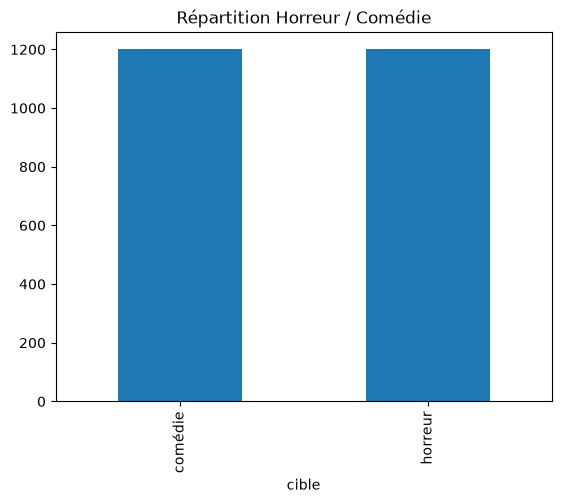

In [3]:
# Répartition des catégories
print("Répartition des catégories :")
print(df["cible"].map({0: "0 : comédie", 1: "1 : horreur"}).value_counts())

# Visualisation
df["cible"].map({0: "comédie", 1: "horreur"}).value_counts().plot(kind="bar", title="Répartition Horreur / Comédie")
plt.show()

count    2400.000000
mean       96.701667
std        61.264467
min        30.000000
25%        59.000000
50%        82.000000
75%       117.000000
max      1287.000000
Name: nb_mots, dtype: float64


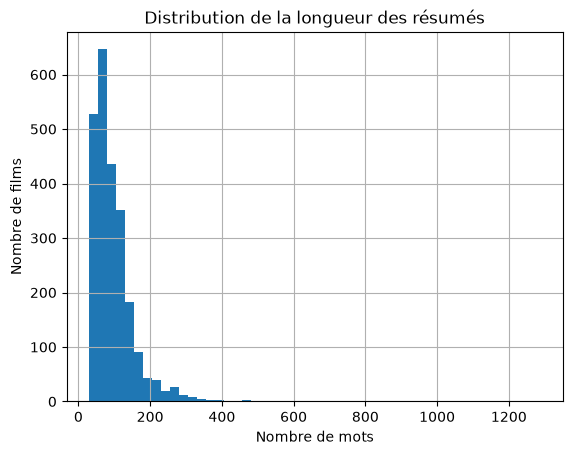

In [4]:
# Longueur des textes (en nombre de mots)
# Adapter le nom de la colonne resume selon le CSV
colonne_resume = "resume"
df["nb_mots"] = df[colonne_resume].astype(str).apply(lambda x: len(x.split()))

print(df["nb_mots"].describe())

# Visualisation de la distribution
df["nb_mots"].hist(bins=50)
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre de films")
plt.title("Distribution de la longueur des résumés")
plt.show()

In [5]:
# Nettoyage : suppression des espaces en trop et des doublons
nb_avant = len(df)

# Suppression des espaces en début/fin et normalisation des espaces multiples
df[colonne_resume] = df[colonne_resume].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)

# Suppression des doublons (lignes identiques)
df = df.drop_duplicates()

# Suppression des doublons sur le texte uniquement (même résumé, catégorie différente = suspect)
df = df.drop_duplicates(subset=[colonne_resume])

nb_apres = len(df)
print(f"Lignes avant nettoyage : {nb_avant}")
print(f"Lignes après nettoyage : {nb_apres}")
print(f"Lignes supprimées : {nb_avant - nb_apres}")

Lignes avant nettoyage : 2400
Lignes après nettoyage : 2346
Lignes supprimées : 54


In [6]:
# Vérification de la répartition après nettoyage
print("\nRépartition après nettoyage :")
print(df["cible"].map({0: "0 : comédie", 1: "1 : horreur"}).value_counts())


Répartition après nettoyage :
cible
0 : comédie    1195
1 : horreur    1151
Name: count, dtype: int64


### 📝 Note d'audit

> *À compléter : en une phrase, ce que vous avez trouvé et ce que vous avez corrigé.*

> Le jeu de données initial contient 2400 lignes réparties en 1200 horreur(1) et 1200 comédie(0) . Après nettoyage, on a supprimé 54 doublons et normalisé les espaces. Les textes font en moyenne ~97 mots.

> Le jeu de données final contient 2346 lignes réparties en 1195 comédie pour 1151 films d'horreurs.


---
## 2️⃣ Découpage du jeu de données

**Objectif :** Séparer les textes en trois parties :
- **60 %** apprentissage (train)
- **20 %** test
- **20 %** production (à garder de côté, on n'y touche pas)

Garder la même proportion d'horreur et de comédie dans chaque partie (`stratify`).

In [7]:
# Séparation des features (X) et de la cible (y)
colonne_texte = "resume"
colonne_label = "cible"

X = df[colonne_texte]
y = df[colonne_label]

# Premier split : 80% (train+val) / 20% (test)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

# Deuxième split : 75% de temp = 60% du total (train) / 25% de temp = 20% du total (production)
X_train, X_prod, y_train, y_prod = train_test_split(X_temp, y_temp, test_size=0.25, random_state=SEED, stratify=y_temp)

In [8]:
print(f"Train      : {len(X_train)} ({len(X_train) / len(df):.1%})")
print(f"Test       : {len(X_test)} ({len(X_test) / len(df):.1%})")
print(f"Production : {len(X_prod)} ({len(X_prod) / len(df):.1%})")

# Vérification de la stratification
print("\nProportions exactes :")
print(f"  Train      : {y_train.value_counts(normalize=True).round(3).to_dict()}")
print(f"  Test       : {y_test.value_counts(normalize=True).round(3).to_dict()}")
print(f"  Production : {y_prod.value_counts(normalize=True).round(3).to_dict()}")

Train      : 1407 (60.0%)
Test       : 470 (20.0%)
Production : 469 (20.0%)

Proportions exactes :
  Train      : {0: 0.51, 1: 0.49}
  Test       : {0: 0.509, 1: 0.491}
  Production : {0: 0.51, 1: 0.49}


---
## 3️⃣ Représentation du texte (TF-IDF)

**Objectif :** Transformer chaque texte en nombres avec un TF-IDF.

⚠️ **Important :** Apprendre le vocabulaire sur l'**apprentissage seulement**, puis transformer les trois parties avec ce même objet.

In [9]:
# Création et ajustement du vectoriseur TF-IDF sur le train uniquement
vectoriseur = TfidfVectorizer(
    max_features=10042,  # Limite du vocabulaire
    # Unigrammes (mot seul) et bigrammes (paire de mot, ex: "machine learning"). Les bigrammes capturent du contexte que les mots isolés perdent.
    ngram_range=(
        1,
        2,
    ),
    min_df=2,  # Ignore les termes présents dans moins de 2 documents
    max_df=0.95,  # Ignore les termes présents dans plus de 95% des documents
    # Liste de stopwords anglais de scikit-learn (the, and, is, ...) (pas de stop words français par défaut)
    stop_words="english",
)

# Apprentissage sur le train uniquement
X_train = vectoriseur.fit_transform(X_train)

# Transformation des autres parties avec le même vectoriseur
X_test = vectoriseur.transform(X_test)
X_prod = vectoriseur.transform(X_prod)

print(f"Dimensions train : {X_train.shape}")
print(f"Dimensions test  : {X_test.shape}")
print(f"Vocabulaire      : {len(vectoriseur.vocabulary_)} termes")

Dimensions train : (1407, 9005)
Dimensions test  : (470, 9005)
Vocabulaire      : 9005 termes


---
## 4️⃣ Les points de comparaison

**Objectif :** Entraîner trois modèles et mesurer le F1 de chacun sur **5 graines différentes**.

| Modèle | Description |
|--------|-------------|
| Régression logistique | Modèle linéaire de référence |
| Bayes naïf (MultinomialNB) | Modèle probabiliste de référence |
| Réseau de neurones simple | 1 couche cachée, un peu de dropout, aucun réglage particulier |

**Marge de bruit :** `1,96 × √(p(1-p)/n)` avec `p` = score F1 et `n` = taille de l'échantillon de validation.

In [10]:
# Fonction pour calculer la marge de bruit
def marge_de_bruit(p: float, n: int) -> float:
    """Calcule la marge de bruit à 95% pour un score F1."""
    return 1.96 * np.sqrt(p * (1 - p) / n)


n_val = X_test.shape[0]
print(f"Taille validation : {n_val}")

Taille validation : 470


In [11]:
# ─── Modèle 1 : Régression logistique ─────────────────────────────────────
SEEDS = [42, 123, 456, 789, 2026]
results = {"LogReg": [], "Bayes naïf": [], "NN_simple": []}

for seed in SEEDS:
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Régression logistique
    logreg = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=seed)  # lbfgs est le solveur par défaut
    logreg.fit(X_train, y_train)
    y_pred_lr = logreg.predict(X_test)
    f1_lr = f1_score(y_test, y_pred_lr)
    results["LogReg"].append(f1_lr)

    # Bayes naïf
    bn = MultinomialNB()
    bn.fit(X_train, y_train)
    y_pred_bn = bn.predict(X_test)
    f1_bn = f1_score(y_test, y_pred_bn)
    results["Bayes naïf"].append(f1_bn)

In [12]:
print("\nF1 scores finaux sur 5 graines :")
for model, scores in results.items():
    if scores:  # Si la liste n'est pas vide
        moyenne = np.mean(scores)
        std = np.std(scores) if len(scores) > 1 else 0.0
        print(f"  {model:15s} : {moyenne:.4f} ± {std:.4f}  {scores}")
        print(f"    Marge de bruit (n={n_val}) : ±{marge_de_bruit(moyenne, n_val):.4f}")
    else:
        print(f"  {model:15s} : [résultats non disponibles]")


F1 scores finaux sur 5 graines :
  LogReg          : 0.8668 ± 0.0000  [0.8668171557562077, 0.8668171557562077, 0.8668171557562077, 0.8668171557562077, 0.8668171557562077]
    Marge de bruit (n=470) : ±0.0307
  Bayes naïf      : 0.8726 ± 0.0000  [0.8725701943844493, 0.8725701943844493, 0.8725701943844493, 0.8725701943844493, 0.8725701943844493]
    Marge de bruit (n=470) : ±0.0301
  NN_simple       : [résultats non disponibles]


In [13]:
# ─── Modèle 3 : Réseau de neurones simple ─────────────────────────────────
def creer_rnn_simple(input_dim: int, seed: int = SEED):
    """Réseau de départ très simple : 1 couche cachée, un peu de dropout."""
    tf.random.set_seed(seed)
    modele = keras.Sequential(
        [
            layers.Input(shape=(input_dim,)),
            layers.Dense(32, activation="relu"),
            layers.Dropout(0.3),
            layers.Dense(1, activation="sigmoid"),
        ]
    )
    modele.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return modele


# Conversion en dense pour Keras
X_train_dense = X_train.toarray().astype("float32")
X_test_dense = X_test.toarray().astype("float32")

input_dim = X_train_dense.shape[1]

for seed in SEEDS:
    np.random.seed(seed)
    tf.random.set_seed(seed)

    modele = creer_rnn_simple(input_dim, seed)
    modele.fit(
        X_train_dense,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VALIDATION_SPLIT,
        callbacks=[EarlyStopping(patience=PATIENCE, restore_best_weights=True)],
        verbose=0,
    )

    y_pred_proba = modele.predict(X_test_dense, verbose=0)
    y_pred_rnn = (y_pred_proba > 0.5).astype(int).flatten()
    f1_rnn = f1_score(y_test, y_pred_rnn)
    results["NN_simple"].append(f1_rnn)

In [14]:
print("\nF1 scores finaux sur 5 graines :")
for model, scores in results.items():
    if scores:  # Si la liste n'est pas vide
        moyenne = np.mean(scores)
        std = np.std(scores) if len(scores) > 1 else 0.0
        print(f"  {model:15s} : {moyenne:.4f} ± {std:.4f}  {scores}")
        print(f"    Marge de bruit (n={n_val}) : ±{marge_de_bruit(moyenne, n_val):.4f}")
    else:
        print(f"  {model:15s} : [résultats non disponibles]")


F1 scores finaux sur 5 graines :
  LogReg          : 0.8668 ± 0.0000  [0.8668171557562077, 0.8668171557562077, 0.8668171557562077, 0.8668171557562077, 0.8668171557562077]
    Marge de bruit (n=470) : ±0.0307
  Bayes naïf      : 0.8726 ± 0.0000  [0.8725701943844493, 0.8725701943844493, 0.8725701943844493, 0.8725701943844493, 0.8725701943844493]
    Marge de bruit (n=470) : ±0.0301
  NN_simple       : 0.8589 ± 0.0037  [0.8626609442060086, 0.8614718614718615, 0.8521739130434782, 0.8602150537634409, 0.8577586206896551]
    Marge de bruit (n=470) : ±0.0315


---
## 5️⃣ Recherche des réglages avec KerasTuner

**Objectif :** Écrire une fonction qui construit un réseau à partir de **cinq réglages** :
- Nombre de couches
- Nombre de neurones
- Dropout
- Régularisation (L2)
- Taux d'apprentissage

Puis lancer **KerasTuner (RandomSearch, 20 essais)**.

In [15]:
# Fonction de construction du modèle avec hyperparamètres réglables
# Construction du modèle à partir de réglages DÉJÀ tirés (fonction pure, agnostique outil)
def construire_modele(reglages: dict, input_dim: int):
    """Construit et compile un réseau à partir de valeurs concrètes."""

    # Initialisation d'un modèle séquentiel (empilement linéaire de couches)
    modele = keras.Sequential()

    # Ajout de la couche d'entrée avec la dimension spécifiée
    modele.add(layers.Input(shape=(input_dim,)))

    # Parcourir chaque couche définie dans les réglages
    for couche in reglages["couches"]:
        # Ajouter une couche Dense (pleinement connectée) avec :
        # - nombre de neurones spécifié dans les réglages
        # - activation ReLU (Rectified Linear Unit)
        # - régularisation L2 pour limiter les poids trop grands (coefficient depuis réglages)
        modele.add(
            layers.Dense(
                couche["neurones"],
                activation="relu",
                kernel_regularizer=regularizers.l2(couche["l2"]),
            )
        )

        # Ajouter une couche Dropout pour désactiver aléatoirement des neurones
        # (taux de dropout spécifié dans les réglages, ex: 0.2 = 20% de neurones désactivés)
        modele.add(layers.Dropout(couche["dropout"]))

    # Ajouter la couche de sortie :
    # - 1 neurone (classification binaire)
    # - activation sigmoid pour une sortie entre 0 et 1
    modele.add(layers.Dense(1, activation="sigmoid"))

    # Compiler le modèle avec :
    # - optimiseur Adam (adaptatif, efficace pour la plupart des cas)
    # - taux d'apprentissage spécifié dans les réglages
    # - fonction de perte : binary_crossentropy (adaptée à la classification binaire)
    # - métrique : accuracy (précision du modèle)
    modele.compile(
        optimizer=keras.optimizers.Adam(learning_rate=reglages["learning_rate"]),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )

    # Retourner le modèle compilé et prêt à l'entraînement
    return modele

In [16]:
# Plages de recherche : LA source unique de vérité, partagée par KerasTuner et Optuna.
# Chaque entrée : "min", "max", et soit "step" (valeurs discrètes) soit "log": True (continu log-uniforme).
PLAGES = {
    "nb_couches": {"min": 1, "max": 3, "step": 1},
    "neurones": {"min": 32, "max": 256, "step": 32},
    "l2": {"valeurs": [1e-5, 5e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2]},
    "learning_rate": {"valeurs": [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]},
    "dropout": {"valeurs": [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]},
}

In [17]:
def _faire_tireur(objet):
    """Adapte hp (KerasTuner) ou trial (Optuna) en deux fonctions uniformes : entier / choix.

    Problème résolu : les deux outils tirent des valeurs de la même façon
    (« donne-moi une valeur pour ce paramètre ») mais avec des noms de
    méthodes différents (hp.Int vs trial.suggest_int, hp.Choice vs
    trial.suggest_categorical). Cette fonction fabrique donc, pour l'objet
    reçu, DEUX mini-fonctions (entier / choix) qui parlent le MÊME langage,
    quel que soit l'outil. Le reste du code n'a plus jamais besoin de savoir
    qui tire en dessous.
    """
    # Identification explicite de l'outil par son type :
    # un objet inconnu échoue clairement au lieu de prendre un mauvais chemin
    if isinstance(objet, optuna.Trial):
        # ---- Cas Optuna : on enveloppe trial.suggest_* dans notre interface ----
        return (
            # entier("nom", mini, maxi, pas) → trial.suggest_int
            lambda nom, mini, maxi, pas=1: objet.suggest_int(nom, mini, maxi, step=pas),
            # choix("nom", valeurs) → trial.suggest_categorical
            # tire uniformément dans une LISTE explicite (ex: l2 ∈ {1e-5, 3e-5, …, 1e-2})
            lambda nom, valeurs: objet.suggest_categorical(nom, valeurs),
        )
    if isinstance(objet, kt.HyperParameters):
        # ---- Cas KerasTuner : on enveloppe hp.Int / hp.Choice dans la même interface ----
        return (
            # entier("nom", mini, maxi, pas) → hp.Int
            lambda nom, mini, maxi, pas=1: objet.Int(nom, min_value=mini, max_value=maxi, step=pas),
            # choix("nom", valeurs) → hp.Choice
            lambda nom, valeurs: objet.Choice(nom, values=valeurs),
        )
    # Échec rapide et explicite si on passe autre chose qu'un hp ou un trial
    raise TypeError(f"Objet non supporté pour le tirage : {type(objet).__name__}")


def tirer_reglages(objet, plages: dict = PLAGES) -> dict:
    """Tire une combinaison d'hyperparamètres — objet = hp (KerasTuner) OU trial (Optuna).

    Renvoie un dict imbriqué, LE contrat commun de tout le notebook :
        {"nb_couches": 2, "couches": [{"neurones":…, "l2":…, "dropout":…}, …],
         "learning_rate": 0.003}
    `construire_modele` ne consomme QUE ce format, jamais un hp ni un trial.
    """
    # Les deux mini-fonctions adaptées à l'objet reçu (Optuna ou KerasTuner).
    entier, choix = _faire_tireur(objet)

    # 1) Le nombre de couches est tiré EN PREMIER, car il commande la suite :
    #    c'est lui qui décide combien de blocs neurones_{i}/l2_{i}/dropout_{i}
    #    existeront (espace de recherche dynamique/conditionnel).
    nb_couches = entier(
        "nb_couches",
        plages["nb_couches"]["min"],
        plages["nb_couches"]["max"],
        pas=plages["nb_couches"].get("step", 1),
    )

    # 2) Le taux d'apprentissage : tirage uniforme dans la liste de PLAGES
    learning_rate = choix("learning_rate", plages["learning_rate"]["valeurs"])

    # 3) Une entrée par couche cachée. Convention de nommage neurones_{i}, l2_{i},
    #    dropout_{i} : ce sont les MÊMES noms dans les deux outils — c'est ce qui
    #    permet à best_params_vers_reglages() (étapes 6-7) de relire les résultats
    #    des deux sous le même format plat.
    couches = []
    for i in range(nb_couches):
        couches.append(
            {
                # Nb de neurones de la couche i (plage d'entiers : 32, 64, …, 256)
                "neurones": entier(
                    f"neurones_{i}",
                    plages["neurones"]["min"],
                    plages["neurones"]["max"],
                    pas=plages["neurones"].get("step", 1),
                ),
                # Régularisation L2 de la couche i (liste : 1e-5, 3e-5, …, 1e-2)
                "l2": choix(f"l2_{i}", plages["l2"]["valeurs"]),
                # Dropout de la couche i (liste : 0.0, 0.1, …, 0.5)
                "dropout": choix(f"dropout_{i}", plages["dropout"]["valeurs"]),
            }
        )

    # Le dict de sortie : valeurs concrètes, plus aucun lien avec un outil
    return {"nb_couches": nb_couches, "couches": couches, "learning_rate": learning_rate}

In [18]:
# Lancement de la recherche KerasTuner (RandomSearch, 20 essais)
tuner = kt.RandomSearch(
    # KerasTuner appelle cette fonction à chaque essai en lui passant un hp.
    # Le hp est détecté par _faire_tireur → tirer_reglages tire les valeurs
    # dans PLAGES → construire_modele assemble le modèle concret.
    lambda hp: construire_modele(tirer_reglages(hp), input_dim),
    objective="val_accuracy",  # métrique à maximiser pour classer les essais
    max_trials=20,  # 20 combinaisons testées (autant qu'Optuna à l'étape 6)
    executions_per_trial=1,  # chaque combinaison entraînée une seule fois
    directory="keras_tuner_dir",  # où les essais sont sauvegardés
    project_name="classification_films",
    overwrite=True,  # repart de zéro à chaque exécution (évite errno 22 sous Windows)
    seed=SEED,
)

# La recherche : pour chacun des 20 essais, le tuner tire une combinaison
# (via le lambda), entraîne le modèle et enregistre le meilleur val_accuracy.
tuner.search(
    X_train_dense,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[EarlyStopping(patience=PATIENCE, restore_best_weights=True)],
    verbose=0,
)

In [19]:
# Meilleurs hyperparamètres : best_hps = objet HyperParameters du gagnant.
# Astuce : best_hps.values est un dict PLAT au même format que study.best_params
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\nMeilleurs hyperparamètres (KerasTuner) :")
for param in ["nb_couches", "learning_rate"]:
    print(f"  {param}: {best_hps.get(param)}")
for i in range(best_hps.get("nb_couches")):
    print(
        f"  couche {i}: neurones={best_hps.get(f'neurones_{i}')}, "
        f"dropout={best_hps.get(f'dropout_{i}')}, l2={best_hps.get(f'l2_{i}')}"
    )


Meilleurs hyperparamètres (KerasTuner) :
  nb_couches: 2
  learning_rate: 0.0001
  couche 0: neurones=128, dropout=0.5, l2=5e-05
  couche 1: neurones=32, dropout=0.0, l2=1e-05


In [20]:
# Évaluation du meilleur modèle KerasTuner sur le TEST
# (dans ce TP, le set "test" sert à la recherche et à la comparaison des outils ;
#  le hold-out final "prod" ne sera mesuré qu'à l'étape 7)

# Reconstruit le modèle du meilleur essai à partir des hyperparamètres gagnants
# (via notre lambda hp → construire_modele), puis recharge les poids sauvegardés
# pendant la recherche : modèle déjà entraîné, pas de fit ici.
best_model_kt = tuner.get_best_models(num_models=1)[0]

# Prédictions sur le test : le réseau sort une probabilité (sigmoid), le seuil
# 0.5 la convertit en classe ; .astype(int) + .flatten() → vecteur 1D de labels
# 0/1, format attendu par f1_score.
y_pred_kt = (best_model_kt.predict(X_test_dense, verbose=0) > 0.5).astype(int).flatten()

# F1 sur le test — même métrique et même jeu que le meilleur modèle Optuna
# (étape 6) : c'est ce qui rendra la comparaison des deux F1 honnête.
f1_kt = f1_score(y_test, y_pred_kt)

# n_val = taille du set de test (défini plus haut : n_val = X_test.shape[0]).
# Si l'écart KT vs Optuna reste sous la marge, aucun gagnant déclarable.
print(f"F1 KerasTuner (meilleur modèle) : {f1_kt:.4f}")
print(f"Marge de bruit : ±{marge_de_bruit(f1_kt, n_val):.4f}")

/home/romain/venvs/DeepLearning_Create_Optimize_PushToProd/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


F1 KerasTuner (meilleur modèle) : 0.8421
Marge de bruit : ±0.0330


---
## 6️⃣ Recherche des réglages avec Optuna

**Objectif :** Refaire la même recherche avec **Optuna**, sur exactement les mêmes réglages, les mêmes valeurs possibles, le même nombre d'essais (20), en réutilisant la fonction `construire_modele`.

**Comparer** le meilleur score des deux outils, en tenant compte de la marge de bruit.

In [21]:
# ============================================================
# Fonction objectif pour Optuna
# ============================================================
def objectif_optuna(trial):
    """
    Fonction à maximiser par Optuna.

    Pour que la comparaison avec KerasTuner soit équitable, on réutilise
    exactement les mêmes éléments :
      - le même tirage des hyperparamètres (même espace de recherche)
      - la même construction de modèle
      - les mêmes réglages d'entraînement
      - le même critère de sélection (la val_accuracy)
    """
    # `trial` : objet fourni par Optuna à chaque essai, qui expose
    # les méthodes suggest_* pour piocher les hyperparamètres.
    # On appelle la MÊME fonction que côté KerasTuner → mêmes bornes,
    # mêmes choix possibles, comparaison équitable.
    reglages = tirer_reglages(trial)

    # Construction du modèle avec les hyperparamètres tirés
    # (input_dim = nombre de features en entrée)
    modele = construire_modele(reglages, input_dim)

    # --- Entraînement : mêmes réglages que tuner.search ---
    history = modele.fit(
        X_train_dense,  # données d'entraînement (format dense attendu par Keras)
        y_train,  # labels
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VALIDATION_SPLIT,
        callbacks=[
            EarlyStopping(
                patience=PATIENCE,
                restore_best_weights=True,  # on restaure les poids de la meilleure époque
            )
        ],
        verbose=0,  # silencieux
    )

    # --- Score renvoyé à Optuna ---
    # max(...) = la meilleure val_accuracy observée pendant l'entraînement,
    # exactement l'équivalent de l'oracle OBJECTIVE_VAL_ACCURACY de KerasTuner.
    # NB : le max est nécessaire car la meilleure époque n'est pas forcément
    # la dernière (l'early stopping peut couper après un plateau).
    return max(history.history["val_accuracy"])


# ============================================================
# Création de l'étude et lancement de la recherche
# ============================================================

# direction="maximize" : on cherche à maximiser la val_accuracy
# (par défaut Optuna minimise, d'où l'argument explicite).
study = optuna.create_study(
    study_name="classification_films_optuna",
    direction="maximize",
    # RandomSampler + seed : tirage aléatoire uniforme dans l'espace de
    # recherche, équivalent au RandomSearch de KerasTuner.
    # Le seed garantit la reproductibilité (mêmes tirages à chaque exécution).
    sampler=optuna.samplers.RandomSampler(seed=SEED),
)

# Lancement de l'optimisation :
# - objectif_optuna : la fonction à maximiser (1 trial = 1 tirage + 1 entraînement)
# - n_trials=20     : 20 combinaisons testées, comme pour KerasTuner
# - show_progress_bar : barre de progression dans la console
study.optimize(objectif_optuna, n_trials=20, show_progress_bar=True)

[I 2026-10-28 14:02:09,317] A new study created in memory with name: classification_films_optuna
Best trial: 0. Best value: 0.899408:   5%|▎     | 1/20 [00:39<12:22, 39.07s/it]

[I 2026-10-28 14:02:48,384] Trial 0 finished with value: 0.8994082808494568 and parameters: {'nb_couches': 2, 'learning_rate': 0.0001, 'neurones_0': 32, 'l2_0': 0.001, 'dropout_0': 0.3, 'neurones_1': 160, 'l2_1': 0.001, 'dropout_1': 0.5}. Best is trial 0 with value: 0.8994082808494568.


Best trial: 0. Best value: 0.899408:  10%|▌     | 2/20 [00:59<08:27, 28.17s/it]

[I 2026-10-28 14:03:08,927] Trial 1 finished with value: 0.8934911489486694 and parameters: {'nb_couches': 3, 'learning_rate': 0.0001, 'neurones_0': 32, 'l2_0': 0.0001, 'dropout_0': 0.2, 'neurones_1': 160, 'l2_1': 1e-05, 'dropout_1': 0.0, 'neurones_2': 32, 'l2_2': 1e-05, 'dropout_2': 0.4}. Best is trial 0 with value: 0.8994082808494568.


Best trial: 0. Best value: 0.899408:  15%|▉     | 3/20 [01:07<05:23, 19.00s/it]

...

[I 2026-10-28 14:08:41,175] Trial 17 finished with value: 0.8875739574432373 and parameters: {'nb_couches': 2, 'learning_rate': 0.01, 'neurones_0': 32, 'l2_0': 5e-05, 'dropout_0': 0.5, 'neurones_1': 192, 'l2_1': 0.005, 'dropout_1': 0.0}. Best is trial 3 with value: 0.9053254723548889.


Best trial: 3. Best value: 0.905325:  95%|████▊| 19/20 [06:43<00:15, 15.16s/it]

[I 2026-10-28 14:08:52,442] Trial 18 finished with value: 0.88165682554245 and parameters: {'nb_couches': 1, 'learning_rate': 0.005, 'neurones_0': 160, 'l2_0': 5e-05, 'dropout_0': 0.3}. Best is trial 3 with value: 0.9053254723548889.


Best trial: 19. Best value: 0.91716: 100%|█████| 20/20 [07:53<00:00, 23.69s/it]

[I 2026-10-28 14:10:03,193] Trial 19 finished with value: 0.9171597361564636 and parameters: {'nb_couches': 3, 'learning_rate': 0.0001, 'neurones_0': 256, 'l2_0': 0.0001, 'dropout_0': 0.3, 'neurones_1': 256, 'l2_1': 0.0005, 'dropout_1': 0.3, 'neurones_2': 256, 'l2_2': 0.01, 'dropout_2': 0.5}. Best is trial 19 with value: 0.9171597361564636.


In [22]:
# Meilleurs hyperparamètres Optuna
print("Meilleurs hyperparamètres (Optuna) :")
best_params_optuna = study.best_params
for key, value in best_params_optuna.items():
    print(f"  {key}: {value}")

# Réentraînement du meilleur modèle Optuna pour obtenir le F1
# (reconstruction avec les meilleurs paramètres)
best_model_optuna = keras.Sequential()
best_model_optuna.add(layers.Input(shape=(input_dim,)))

for i in range(best_params_optuna["nb_couches"]):
    best_model_optuna.add(
        layers.Dense(
            best_params_optuna[f"neurones_{i}"],
            activation="relu",
            kernel_regularizer=regularizers.l2(best_params_optuna[f"l2_{i}"]),
        )
    )
    best_model_optuna.add(layers.Dropout(best_params_optuna[f"dropout_{i}"]))

best_model_optuna.add(layers.Dense(1, activation="sigmoid"))
best_model_optuna.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_params_optuna["learning_rate"]),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

best_model_optuna.fit(
    X_train_dense,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[EarlyStopping(patience=PATIENCE, restore_best_weights=True)],
    verbose=0,
)

y_pred_opt = (best_model_optuna.predict(X_test_dense, verbose=0) > 0.5).astype(int).flatten()
f1_opt = f1_score(y_test, y_pred_opt)

print(f"\nF1 Optuna (meilleur modèle) : {f1_opt:.4f}")
print(f"Marge de bruit : ±{marge_de_bruit(f1_opt, n_val):.4f}")

Meilleurs hyperparamètres (Optuna) :
  nb_couches: 3
  learning_rate: 0.0001
  neurones_0: 256
  l2_0: 0.0001
  dropout_0: 0.3
  neurones_1: 256
  l2_1: 0.0005
  dropout_1: 0.3
  neurones_2: 256
  l2_2: 0.01
  dropout_2: 0.5

F1 Optuna (meilleur modèle) : 0.8608
Marge de bruit : ±0.0313


In [23]:
# Comparaison KerasTuner vs Optuna
print("=" * 50)
print("COMPARAISON KerasTuner vs Optuna")
print("=" * 50)
print(f"KerasTuner  : F1 = {f1_kt:.4f} ± {marge_de_bruit(f1_kt, n_val):.4f}")
print(f"Optuna      : F1 = {f1_opt:.4f} ± {marge_de_bruit(f1_opt, n_val):.4f}")
print("-" * 50)

ecart = abs(f1_kt - f1_opt)
marge_max = max(marge_de_bruit(f1_kt, n_val), marge_de_bruit(f1_opt, n_val))

print(f"Écart absolu : {ecart:.4f}")
print(f"Marge de bruit max : {marge_max:.4f}")

if ecart < marge_max:
    print("\n⚠️ L'écart est inférieur à la marge de bruit : on ne peut pas dire qu'un outil est meilleur que l'autre.")
else:
    meilleur = "KerasTuner" if f1_kt > f1_opt else "Optuna"
    print(f"\n✅ L'écart dépasse la marge de bruit : {meilleur} est significativement meilleur.")

COMPARAISON KerasTuner vs Optuna
KerasTuner  : F1 = 0.8421 ± 0.0330
Optuna      : F1 = 0.8608 ± 0.0313
--------------------------------------------------
Écart absolu : 0.0187
Marge de bruit max : 0.0330

⚠️ L'écart est inférieur à la marge de bruit : on ne peut pas dire qu'un outil est meilleur que l'autre.


---
## 7️⃣ Verdict sur le test

**Objectif :**
1. Prendre les meilleurs réglages (du meilleur outil)
2. Réentraîner le réseau sur **tout l'apprentissage** (train + validation)
3. Sur **5 graines**
4. Comparer avec le réseau de départ et le meilleur modèle simple
5. Mesurer sur le **test, une seule fois**
6. Conclure honnêtement

In [24]:
# Réentraînement du meilleur modèle sur tout l'apprentissage, 5 graines
# Utiliser les meilleurs hyperparamètres trouvés (KerasTuner ou Optuna)


def best_params_vers_reglages(best_params) -> dict:
    """Reconvertit le dict PLAT des meilleurs hyperparamètres au format imbriqué.

    Problème résolu : best_params_optuna (Optuna) et best_hps (KerasTuner)
    stockent les réglages À PLAT (neurones_0, l2_0, dropout_0, …), alors que
    construire_modele (étape 5) consomme le format imbriqué produit par
    tirer_reglages : {"nb_couches": …, "couches": [{"neurones", "l2", "dropout"}…],
    "learning_rate": …}. Cette fonction fait le pont entre les deux, quel que
    soit l'outil gagnant.
    """
    # KerasTuner fournit un objet HyperParameters, pas un dict :
    # .values redonne le dict plat aux MÊMES noms que study.best_params (Optuna).
    if isinstance(best_params, kt.HyperParameters):
        best_params = best_params.values

    # Reconstruction de la liste de couches à partir des noms plats
    # neurones_{i} / l2_{i} / dropout_{i}, pour i de 0 à nb_couches - 1.
    couches = [
        {
            "neurones": best_params[f"neurones_{i}"],
            "l2": best_params[f"l2_{i}"],
            "dropout": best_params[f"dropout_{i}"],
        }
        for i in range(best_params["nb_couches"])
    ]

    # Le dict de sortie : le même contrat que celui de tirer_reglages.
    return {
        "nb_couches": best_params["nb_couches"],
        "couches": couches,
        "learning_rate": best_params["learning_rate"],
    }

In [25]:
# Sélection automatique du gagnant : le F1 le plus élevé sur le test l'emporte.
# best_params_vers_reglages accepte les deux formats (HyperParameters ou dict plat).
gagnant, best_hps_final = ("KerasTuner", best_hps) if f1_kt > f1_opt else ("Optuna", best_params_optuna)
print(f"Le gagnant est {gagnant}, ses paramètres seront appliqués au modèle final.")

# Conversion une seule fois, hors boucle : les graines changent les poids
# initiaux, jamais les réglages du réseau.
reglages_finaux = best_params_vers_reglages(best_hps_final)

f1_test_scores = []

for seed in SEEDS:
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Construction du modèle : RÉUTILISATION de la fonction de l'étape 5.
    # Plus aucune duplication ici — mêmes couches, même compile, une seule
    # source de vérité pour tout le notebook.
    modele = construire_modele(reglages_finaux, input_dim)

    # Entraînement sur tout le train
    modele.fit(
        X_train_dense,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VALIDATION_SPLIT,
        callbacks=[EarlyStopping(patience=PATIENCE, restore_best_weights=True)],
        verbose=0,
    )

    # Évaluation sur le test (une seule fois par graine)
    y_pred_test = (modele.predict(X_test_dense, verbose=0) > 0.5).astype(int).flatten()
    f1 = f1_score(y_test, y_pred_test)
    f1_test_scores.append(f1)

f1_test_moyen = np.mean(f1_test_scores)
f1_test_std = np.std(f1_test_scores)
n_test = len(y_test)

Le gagnant est Optuna, ses paramètres seront appliqués au modèle final.


In [26]:
print(f"\n{'=' * 50}")
print(f"RÉSULTAT FINAL SUR LE TEST")
print(f"{'=' * 50}")
print(f"F1 moyen : {f1_test_moyen:.4f} ± {f1_test_std:.4f}")
print(f"Scores   : {f1_test_scores}")
print(f"Marge de bruit (n={n_test}) : ±{marge_de_bruit(f1_test_moyen, n_test):.4f}")


RÉSULTAT FINAL SUR LE TEST
F1 moyen : 0.8597 ± 0.0034
Scores   : [0.8589743589743589, 0.861995753715499, 0.853448275862069, 0.860813704496788, 0.8632478632478633]
Marge de bruit (n=470) : ±0.0314


In [27]:
# Comparaison avec les modèles de référence
# Pas de réentraînement ici : les modèles de référence (étape 4) ont été
# entraînés sur le MÊME train et évalués sur le MÊME test que le réseau
# optimisé ci-dessus. On réutilise donc directement leurs F1 — moyenne des
# 5 graines déjà calculée en haut du notebook, stockée dans `results`.
print("Comparaison avec les modèles de référence :")

# Moyennes sur les 5 graines de l'étape 4 (déjà calculées, rien à refaire)
f1_logreg_test = np.mean(results["LogReg"])
f1_nb_test = np.mean(results["Bayes naïf"])
f1_nn_simple_test = np.mean(results["NN_simple"])  # le réseau de départ

print(f"  Régression logistique : F1 = {f1_logreg_test:.4f}")
print(f"  Bayes naïf            : F1 = {f1_nb_test:.4f}")
print(f"  Réseau de départ      : F1 = {f1_nn_simple_test:.4f}")
print(f"  Réseau optimisé       : F1 = {f1_test_moyen:.4f}")

# Marge de bruit
marge = marge_de_bruit(f1_test_moyen, n_test)
print(f"\n  Marge de bruit : ±{marge:.4f}")

# Conclusion
print("\n" + "=" * 50)
print("CONCLUSION")
print("=" * 50)

meilleur_simple = max(f1_logreg_test, f1_nb_test)
if f1_test_moyen - meilleur_simple > marge:
    print(f"✅ Le réseau optimisé ({f1_test_moyen:.4f}) est significativement")
    print(f"   meilleur que le meilleur modèle simple ({meilleur_simple:.4f}).")
elif abs(f1_test_moyen - meilleur_simple) <= marge:
    print(f"⚠️  L'écart entre le réseau optimisé ({f1_test_moyen:.4f}) et le")
    print(f"   meilleur modèle simple ({meilleur_simple:.4f}) est inférieur à la marge de bruit.")
    print(f"   On ne peut pas conclure que le réseau est meilleur.")
else:
    print(f"❌ Le réseau optimisé ({f1_test_moyen:.4f}) n'est pas meilleur")
    print(f"   que le meilleur modèle simple ({meilleur_simple:.4f}).")

Comparaison avec les modèles de référence :
  Régression logistique : F1 = 0.8668
  Bayes naïf            : F1 = 0.8726
  Réseau de départ      : F1 = 0.8589
  Réseau optimisé       : F1 = 0.8597

  Marge de bruit : ±0.0314

CONCLUSION
⚠️  L'écart entre le réseau optimisé (0.8597) et le
   meilleur modèle simple (0.8726) est inférieur à la marge de bruit.
   On ne peut pas conclure que le réseau est meilleur.


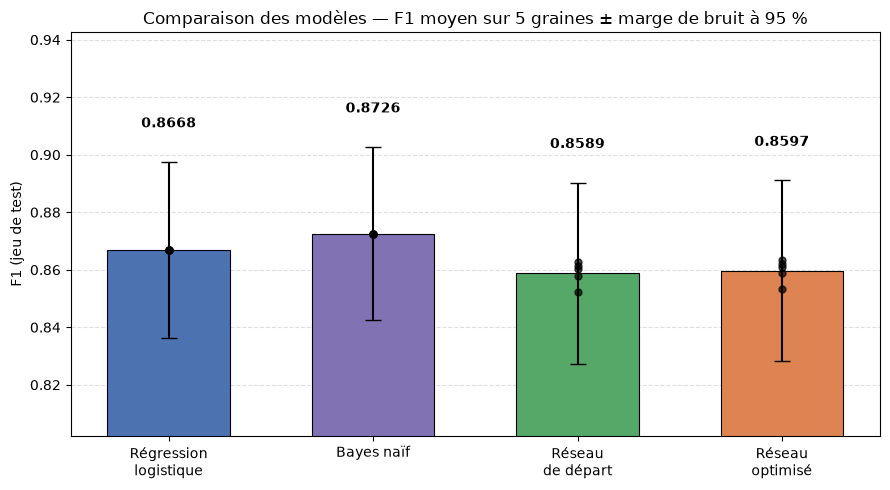

In [28]:
# Comparaison graphique des modèles — F1 sur le jeu de test
# Barres : F1 moyen. Barres d'erreur : marge de bruit à 95 % (le critère
# de décision du TP). Points : les 5 graines individuelles.
fig, ax = plt.subplots(figsize=(9, 5))

# Les 4 modèles du tableau de comparaison, dans le même ordre
modeles = ["Régression\nlogistique", "Bayes naïf", "Réseau\nde départ", "Réseau\noptimisé"]
moyennes = [f1_logreg_test, f1_nb_test, f1_nn_simple_test, f1_test_moyen]
scores_par_graine = [results["LogReg"], results["Bayes naïf"], results["NN_simple"], f1_test_scores]

# Marge de bruit de chaque modèle (dépend de son F1, même taille de test n_test)
marges = [marge_de_bruit(m, n_test) for m in moyennes]

# Couleurs : le réseau optimisé (le héros du TP) se distingue
couleurs = ["#4C72B0", "#8172B3", "#55A868", "#DD8452"]

barres = ax.bar(
    modeles,
    moyennes,
    color=couleurs,
    edgecolor="black",
    linewidth=0.8,
    width=0.6,
    yerr=marges,
    capsize=6,
    error_kw={"elinewidth": 1.5},
)

# Points individuels : les 5 graines par modèle.
# NB : LogReg et Bayes naïf sont déterministes → leurs points se superposent
# en un seul point, c'est attendu. Les réseaux, eux, varient avec la graine.
for i, scores in enumerate(scores_par_graine):
    ax.scatter([i] * len(scores), scores, color="black", zorder=3, s=25, alpha=0.7)

# Moyenne annotée au-dessus de chaque barre
for i, m in enumerate(moyennes):
    ax.text(i, m + marges[i] + 0.012, f"{m:.4f}", ha="center", fontweight="bold")

# Habillage — l'axe Y est zoomé pour rendre les écarts lisibles
# (les barres ne partent donc pas de 0, d'où l'annotation des valeurs)
ymin = min(min(s) for s in scores_par_graine)
ymax = max(max(s) for s in scores_par_graine)
ax.set_ylim(ymin - 0.05, ymax + 0.07)
ax.set_ylabel("F1 (jeu de test)")
ax.set_title("Comparaison des modèles — F1 moyen sur 5 graines ± marge de bruit à 95 %")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

---
## 8️⃣ Sauvegarde

**Objectif :** Créer un dossier `model/` et y ranger :
- `model.keras` — le réseau au format `.keras`
- `vectoriseur.joblib` — le TF-IDF avec joblib
- `metrics.json` — version du modèle, F1 obtenu sur le test, taille du test, versions des bibliothèques (UTF-8)
- `reference.csv` — un petit échantillon de données de référence

In [29]:
# Réentraînement final du meilleur modèle (graine fixe pour la sauvegarde)
# Mêmes données et mêmes réglages d'entraînement que l'étape 7 : le modèle
# sauvegardé est entraîné EXACTEMENT comme celui qui a produit le verdict,
# le F1 de metrics.json décrit donc bien le modèle livré.
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Construction via la fonction partagée — même source de vérité que l'étape 7
modele_final = construire_modele(reglages_finaux, input_dim)

# Entraînement — mêmes réglages que la boucle sur 5 graines de l'étape 7
modele_final.fit(
    X_train_dense,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[EarlyStopping(patience=PATIENCE, restore_best_weights=True)],
    verbose=1,
)

# Évaluation finale sur le test
y_pred_final = (modele_final.predict(X_test_dense, verbose=0) > 0.5).astype(int).flatten()
f1_final = f1_score(y_test, y_pred_final)
print(f"\nF1 final sur le test : {f1_final:.4f}")

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 7s 93ms/step - accuracy: 0.5178 - loss: 3.2830 - val_accuracy: 0.4734 - val_loss: 3.1399
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.5792 - loss: 3.0140 - val_accuracy: 0.4675 - val_loss: 2.8875
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6002 - loss: 2.7728 - val_accuracy: 0.4675 - val_loss: 2.6599
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6454 - loss: 2.5519 - val_accuracy: 0.5621 - val_loss: 2.4520
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7948 - loss: 2.3453 - val_accuracy: 0.7515 - val_loss: 2.2569
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9168 - loss: 2.1356 - val_accuracy: 0.8343 - val_loss: 2.0614
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9637 - loss: 1.8966 - val_accuracy: 0.8935 - val_loss: 1.8443
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9806 - loss: 1.6084 - val_accuracy: 0.911

In [30]:
# Sauvegarde du modèle
modele_final.save(MODEL_DIR / "model.keras")
print(f"✅ Modèle sauvegardé : {MODEL_DIR / 'model.keras'}")

# Sauvegarde du vectoriseur — celui de l'étape 3, ajusté sur le train :
# c'est lui qui a servi à évaluer le modèle, le couple sauvegardé
# (modèle + vectoriseur) est donc parfaitement cohérent.
joblib.dump(vectoriseur, MODEL_DIR / "vectoriseur.joblib")
print(f"✅ Vectoriseur sauvegardé : {MODEL_DIR / 'vectoriseur.joblib'}")

✅ Modèle sauvegardé : model/model.keras
✅ Vectoriseur sauvegardé : model/vectoriseur.joblib


In [31]:
# Quantification du modèle pour la production (optimisation bonus)
# Principe : TFLite convertit le réseau en format allégé, et la quantification
# dynamique stocke les poids en int8 (1 octet) au lieu de float32 (4 octets)
# → fichier ~4× plus petit, précision quasi identique.
convertisseur = tf.lite.TFLiteConverter.from_keras_model(modele_final)
convertisseur.optimizations = [tf.lite.Optimize.DEFAULT]  # quantification dynamique
modele_quantifie = convertisseur.convert()

chemin_tflite = MODEL_DIR / "model.tflite"
with open(chemin_tflite, "wb") as f:
    f.write(modele_quantifie)
print(f"✅ Modèle quantifié sauvegardé : {chemin_tflite}")

INFO:tensorflow:Assets written to: /tmp/tmpifsg9q08/assets


INFO:tensorflow:Assets written to: /tmp/tmpifsg9q08/assets


Saved artifact at '/tmp/tmpifsg9q08'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 9005), dtype=tf.float32, name='keras_tensor_463')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  124118803555600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124118811144464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124118811144080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124118811145040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124118803547536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124118803546384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124119277705488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124119271524496: TensorSpec(shape=(), dtype=tf.resource, name=None)
✅ Modèle quantifié sauvegardé : model/model.tflite


In [32]:
# Comparaison : modèle original (float32) vs quantifié (int8)
# Même logique que partout dans le notebook : on mesure, puis on conclut
# avec la marge de bruit — pas au doigt mouillé.
taille_keras = (MODEL_DIR / "model.keras").stat().st_size / 1024
taille_tflite = chemin_tflite.stat().st_size / 1024
print(f"Taille model.keras            : {taille_keras:,.1f} Ko")
print(f"Taille model_quantifie.tflite : {taille_tflite:,.1f} Ko ({taille_keras / taille_tflite:.1f}× plus petit)")

# Prédiction avec l'interpréteur TFLite (exemple par exemple)
interprete = tf.lite.Interpreter(model_path=str(chemin_tflite))
interprete.allocate_tensors()
entree = interprete.get_input_details()[0]
sortie = interprete.get_output_details()[0]

y_pred_quantifie = []
for i in range(len(X_test_dense)):
    interprete.set_tensor(entree["index"], X_test_dense[i : i + 1].astype(np.float32))
    interprete.invoke()
    proba = interprete.get_tensor(sortie["index"])[0][0]
    y_pred_quantifie.append(int(proba > 0.5))

f1_quantifie = f1_score(y_test, y_pred_quantifie)
ecart = abs(f1_final - f1_quantifie)
marge_finale = marge_de_bruit(f1_final, n_test)

print(f"\nF1 keras (float32) : {f1_final:.4f}")
print(f"F1 quantifié (int8) : {f1_quantifie:.4f}")
if ecart <= marge_finale:
    print(f"✅ Perte de {ecart:.4f} ≤ marge de bruit (±{marge_finale:.4f}) : la version quantifiée est fidèle.")
else:
    print(f"❌ Perte de {ecart:.4f} > marge de bruit (±{marge_finale:.4f}) : garder la version float32.")

Taille model.keras            : 28,599.6 Ko
Taille model_quantifie.tflite : 2,395.0 Ko (11.9× plus petit)

F1 keras (float32) : 0.8571
F1 quantifié (int8) : 0.8571
✅ Perte de 0.0000 ≤ marge de bruit (±0.0316) : la version quantifiée est fidèle.


/home/romain/venvs/DeepLearning_Create_Optimize_PushToProd/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [33]:
# Création du fichier metrics.json
import datetime  # date_entrainement dynamique — plus de date codée en dur (C1)
# best_hps_final peut être un dict (Optuna) OU un objet HyperParameters
# (KerasTuner) : on récupère toujours un dict plat pour la sérialisation JSON.
hps_metrics = best_hps_final.values if isinstance(best_hps_final, kt.HyperParameters) else best_hps_final

metrics = {
    "model_version": "1.0.0",
    "model_type": "Sequential (Keras)",
    "f1_score_test": round(float(f1_final), 4),
    "f1_score_test_moyen_5_graines": round(float(f1_test_moyen), 4),
    "f1_score_test_std_5_graines": round(float(f1_test_std), 4),
    "test_size": int(n_test),
    "train_size": int(len(y_train)),
    "production_size": int(len(y_prod)),
    "marge_de_bruit": round(float(marge_de_bruit(f1_final, n_test)), 4),
    "quantification": {
        "format": "TFLite, quantification dynamique (poids int8)",
        "taille_modele_keras_ko": round(taille_keras, 1),
        "taille_tflite_ko": round(taille_tflite, 1),
        "f1_quantifie": round(float(f1_quantifie), 4),
        "ecart_vs_float32": round(abs(f1_final - f1_quantifie), 4),
    },
    "meilleurs_hyperparametres": {
        k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in hps_metrics.items()
    },
    "vectoriseur": {
        "type": "TfidfVectorizer",
        "max_features": int(vectoriseur.max_features),  # lu depuis l'objet, plus de valeur codée en dur
        "ngram_range": [1, 2],
        "vocabulaire_size": len(vectoriseur.vocabulary_),
    },
    "bibliotheques": {
        "python": platform.python_version(),
        "tensorflow": tf.__version__,
        "keras": keras.__version__,
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "keras_tuner": kt.__version__,
        "optuna": optuna.__version__,
        "joblib": joblib.__version__,
    },
    "date_entrainement": datetime.date.today().isoformat(),  # dynamique (C1)
    "seed": SEED,
}

with open(MODEL_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print(f"✅ Métriques sauvegardées : {MODEL_DIR / 'metrics.json'}")
print(json.dumps(metrics, indent=2, ensure_ascii=False))

✅ Métriques sauvegardées : model/metrics.json
{
  "model_version": "1.0.0",
  "model_type": "Sequential (Keras)",
  "f1_score_test": 0.8571,
  "f1_score_test_moyen_5_graines": 0.8597,
  "f1_score_test_std_5_graines": 0.0034,
  "test_size": 470,
  "train_size": 1407,
  "production_size": 469,
  "marge_de_bruit": 0.0316,
  "quantification": {
    "format": "TFLite, quantification dynamique (poids int8)",
    "taille_modele_keras_ko": 28599.6,
    "taille_tflite_ko": 2395.0,
    "f1_quantifie": 0.8571,
    "ecart_vs_float32": 0.0
  },
  "meilleurs_hyperparametres": {
    "nb_couches": 3,
    "learning_rate": 0.0001,
    "neurones_0": 256,
    "l2_0": 0.0001,
    "dropout_0": 0.3,
    "neurones_1": 256,
    "l2_1": 0.0005,
    "dropout_1": 0.3,
    "neurones_2": 256,
    "l2_2": 0.01,
    "dropout_2": 0.5
  },
  "vectoriseur": {
    "type": "TfidfVectorizer",
    "max_features": 10042,
    "ngram_range": [
      1,
      2
    ],
    "vocabulaire_size": 9005
  },
  "bibliotheques": {
    "

In [34]:
# Création d'un échantillon de référence (200 exemples par classe)
# NB : X_test / X_prod ont été écrasés par les matrices TF-IDF à l'étape 3.
# On retrouve les textes bruts via les index des labels (y_test, y_prod),
# qui pointent toujours vers les lignes d'origine du DataFrame.
titres_reference = pd.concat(
    [
        df.loc[y_test.index, "titre"],
        df.loc[y_prod.index, "titre"],
    ]
).reset_index(drop=True)

textes_reference = pd.concat(
    [
        df.loc[y_test.index, colonne_texte],
        df.loc[y_prod.index, colonne_texte],
    ]
).reset_index(drop=True)

labels_reference = pd.concat([y_test, y_prod]).reset_index(drop=True)

# Mêmes noms de colonnes que le CSV initial : titre, resume, cible
reference = pd.DataFrame(
    {
        "titre": titres_reference,
        colonne_texte: textes_reference,
        colonne_label: labels_reference,
    }
)

# 200 exemples par classe
reference_sample = reference.groupby(colonne_label).sample(200).reset_index(drop=True)

reference_sample.to_csv(MODEL_DIR / "reference.csv", index=False, encoding="utf-8")
print(f"✅ Référence sauvegardée : {MODEL_DIR / 'reference.csv'} ({len(reference_sample)} lignes)")
reference_sample.head()

✅ Référence sauvegardée : model/reference.csv (400 lignes)


,titre,resume,cible
0,Run Ronnie Run,Run Ronnie Run is a heart warming spin-off fro...,0
1,The Big Kahuna,On the last evening of a convention two seen-i...,0
2,Boomerang,Marcus is a successful advertising executive w...,0
3,Khosla's Nest,K.K. Khosla (Anupam Kher) is a middle class ma...,0
4,Wayne's World 2,"Wayne is back, this time trying to organize a ...",0


In [35]:
# Vérification finale du dossier model/
print("Contenu du dossier model/ :")
for fichier in sorted(MODEL_DIR.iterdir()):
    taille = fichier.stat().st_size / 1024  # en Ko
    print(f"  📄 {fichier.name:25s} ({taille:.1f} Ko)")

Contenu du dossier model/ :
  📄 faux_metrics.json         (1.2 Ko)
  📄 metrics.json              (1.2 Ko)
  📄 model.keras               (28599.6 Ko)
  📄 model.tflite              (2395.0 Ko)
  📄 reference.csv             (236.8 Ko)
  📄 vectoriseur.joblib        (336.4 Ko)


---
## ✅ Fin du notebook

Le notebook s'est exécuté de haut en bas sans erreur. Le dossier `model/` contient :
- `model.keras` — le réseau entraîné
- `vectoriseur.joblib` — le TF-IDF
- `metrics.json` — les métriques et métadonnées
- `reference.csv` — un échantillon de données de référence